# TP 1 — IA Générative : bases de PyTorch

| Informations académiques | Détails |
|---|---|
| **Nom et prénom** | Hachoum Mouad |
| **Filière** | INTELLIGENCE ARTIFICIELLE & SCIENCES DES DONNÉES |
| **Établissement** | EMSI Maarif |
| **Année universitaire** | 2026-2027 |
| **Module** | IA Générative Multimodale |
| **Enseignant** | Pr. Mohamed Youssfi |

**Objectifs :** préparer des données sans fuite d'information, entraîner une
régression, un MLP et un CNN, évaluer leurs prédictions, sauvegarder et recharger
des paramètres.

Ce travail pratique reprend toutes les consignes situées après **« Exercices »** dans le
notebook du professeur. Les titres Iris/MNIST y sont intervertis : on adopte ici
l'ordre demandé : **1. salaires, 2. Iris, 3. MLP MNIST, 4. CNN MNIST**.

**Sources locales :** `Activité pratique Bases de Pytorch.ipynb` (cellules 58 à 105,
indices commençant à 0) et `Part 1- Support IA Générative Multi-Modale - Introduction - Rappels - Pytorch.pdf`.
Le support présente les tenseurs, Autograd et la boucle d'apprentissage (pages
7–18), `train()`/`eval()` et Dropout (page 19), les DataLoader (page 20), les
métriques et la sauvegarde (pages 26–28), ainsi que le MLP MNIST (pages 39–40).
Les exercices sont de l'apprentissage supervisé, préalable aux modèles génératifs.

## 0. Préparation

Exécuter les cellules **dans l'ordre depuis un noyau neuf**, avec le dossier du
projet comme répertoire courant. Toutes les mesures numériques ci-dessous sont
calculées par le code. Les fichiers du professeur ne sont jamais écrits.

In [1]:
import os
# À définir avant l'initialisation de CUDA pour les calculs reproductibles.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import sys
import json
import random
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
import sklearn
get_ipython().run_line_magic("matplotlib", "inline")
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from IPython.display import display, Markdown

def fixer_graines(graine=42):
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(graine)

fixer_graines()
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})
DOSSIER = Path.cwd()
FIGURES = DOSSIER / "figures"
FIGURES.mkdir(exist_ok=True)

def afficher_figure(nom):
    plt.tight_layout()
    plt.savefig(FIGURES / nom, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()

print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__, "| torchvision :", torchvision.__version__)
print("NumPy :", np.__version__, "| scikit-learn :", sklearn.__version__)
print("Appareil :", device)
if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

Python : 3.12.14
PyTorch : 2.9.1+cu128 | torchvision : 0.24.1+cu128
NumPy : 2.5.5 | scikit-learn : 1.7.2
Appareil : cuda
GPU : NVIDIA GeForce RTX 3060 Laptop GPU


## Exercice 1 — Régression linéaire multiple : prédiction du salaire

### 1. Générer et observer les données

**Consignes :** générer les 300 salariés comme dans l'énoncé, afficher les
dimensions de `X` et `y`, le salaire moyen, puis un nuage de points du salaire
selon l'ancienneté, coloré selon l'expertise.

On reprend exactement les tirages du professeur, dans le même ordre, avec
`torch.manual_seed(42)`. La règle fictive est
$salaire = 4000 + 600\,ancienneté + 1500\,expertise + bruit$, avec un bruit
gaussien d'écart-type 500 DH. Les données sont d'abord générées sur CPU.

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH
Dimensions X : torch.Size([300, 2]) | y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


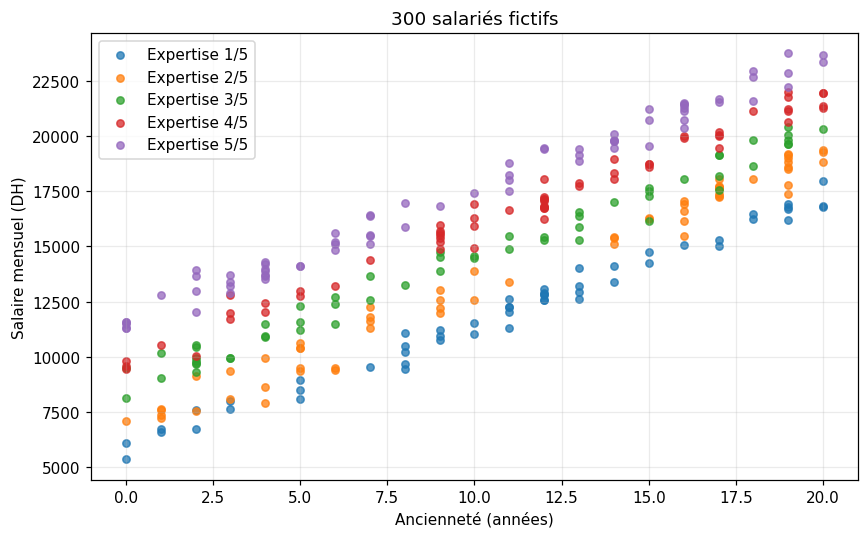

In [2]:
torch.manual_seed(42)
n = 300
anciennete = torch.randint(0, 21, (n, 1)).float()
expertise = torch.randint(1, 6, (n, 1)).float()
bruit = torch.randn(n, 1) * 500
salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit
X_salaire = torch.cat([anciennete, expertise], dim=1)
y_salaire = salaires

for i in range(5):
    print(f"Ancienneté : {X_salaire[i, 0].item():.0f} ans | "
          f"Expertise : {X_salaire[i, 1].item():.0f}/5 | "
          f"Salaire : {y_salaire[i, 0].item():.2f} DH")
print("Dimensions X :", X_salaire.shape, "| y :", y_salaire.shape)
print(f"Salaire moyen : {y_salaire.mean().item():.2f} DH")

plt.figure(figsize=(8, 5))
for niveau in range(1, 6):
    masque = expertise[:, 0] == niveau
    plt.scatter(anciennete[masque, 0], salaires[masque, 0],
                s=23, alpha=0.75, label=f"Expertise {niveau}/5")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("300 salariés fictifs")
plt.legend()
afficher_figure("ex1_salaires.png")

### 2. Séparer et préparer les données

**Consignes :** 80 % entraînement, 20 % test ; standardiser les entrées avec les
statistiques du seul entraînement ; exprimer les salaires en milliers de DH.

On conserve `torch.randperm` et `X_train.std()` de l'énoncé (écart-type corrigé,
division par $n-1$). Le test et les nouveaux salariés utilisent les mêmes moyenne
et écart-type. Les 60 salariés de test ne participent pas à l'apprentissage.

In [3]:
indices = torch.randperm(n)
limite = int(0.8 * n)
train_indices, test_indices = indices[:limite], indices[limite:]
X_train_s = X_salaire[train_indices]
X_test_s = X_salaire[test_indices]
y_train_s = (y_salaire[train_indices] / 1000).to(device)
y_test_s = y_salaire[test_indices] / 1000

moyenne_s = X_train_s.mean(dim=0, keepdim=True)
ecart_type_s = X_train_s.std(dim=0, keepdim=True)
assert torch.all(ecart_type_s > 0)
X_train_s_norm = ((X_train_s - moyenne_s) / ecart_type_s).to(device)
X_test_s_norm = ((X_test_s - moyenne_s) / ecart_type_s).to(device)
assert len(train_indices) == 240 and len(test_indices) == 60
assert not set(train_indices.tolist()) & set(test_indices.tolist())
print("Train :", X_train_s_norm.shape, "| test :", X_test_s_norm.shape)
print("Moyenne train (années, niveau) :", moyenne_s)
print("Écart-type train :", ecart_type_s)
print("Moyenne après standardisation :", X_train_s_norm.mean(dim=0).cpu())

Train : torch.Size([240, 2]) | test : torch.Size([60, 2])
Moyenne train (années, niveau) : tensor([[10.5375,  3.1542]])
Écart-type train : tensor([[6.1228, 1.4396]])
Moyenne après standardisation : tensor([-6.3578e-08, -4.1723e-08])


### 3. Construire et entraîner le modèle

**Consignes :** compléter le modèle et la boucle, puis tracer la perte.
On utilise **`nn.Linear(2, 1)`**, **`MSELoss`**, **SGD, `lr=0.05`**, pendant
**500 époques**, avec toutes les données d'entraînement à chaque époque.
La MSE est exprimée en $(milliers\ de\ DH)^2$.

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391


Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


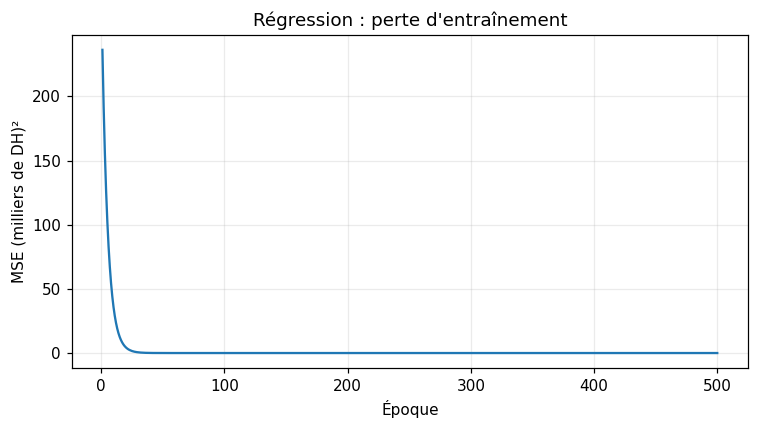

In [4]:
model_salaire = nn.Linear(2, 1).to(device)
criterion_salaire = nn.MSELoss()
optimizer_salaire = torch.optim.SGD(model_salaire.parameters(), lr=0.05)
historique_salaire = []

for epoch in range(500):
    model_salaire.train()
    optimizer_salaire.zero_grad()
    predictions = model_salaire(X_train_s_norm)
    loss = criterion_salaire(predictions, y_train_s)
    loss.backward()
    optimizer_salaire.step()
    historique_salaire.append(loss.item())
    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")

plt.plot(range(1, 501), historique_salaire)
plt.xlabel("Époque")
plt.ylabel("MSE (milliers de DH)²")
plt.title("Régression : perte d'entraînement")
afficher_figure("ex1_perte.png")

### 4. Évaluer les prédictions

**Consigne :** calculer la MAE sur le test après reconversion en DH.
La MAE est $\frac1N\sum_i|\widehat y_i-y_i|$ : elle décrit l'écart absolu moyen
entre les prédictions et les salaires réels. L'exemple « 400 DH » de l'énoncé est
illustratif ; on affiche ici la valeur réellement mesurée.

In [5]:
model_salaire.eval()
with torch.no_grad():
    predictions_dh = model_salaire(X_test_s_norm).cpu() * 1000
    salaires_reels_dh = y_test_s * 1000
    mae_salaire = (predictions_dh - salaires_reels_dh).abs().mean().item()
print(f"Erreur absolue moyenne sur les 60 salariés de test : {mae_salaire:.2f} DH")
display(Markdown(f"Les prédictions s'écartent en moyenne de **{mae_salaire:.2f} DH** "
                 "des salaires réels du jeu de test."))

Erreur absolue moyenne sur les 60 salariés de test : 381.64 DH


Les prédictions s'écartent en moyenne de **381.64 DH** des salaires réels du jeu de test.

### 5. Prédire le salaire d'un nouveau salarié

**Consigne :** prédire pour **7 ans d'ancienneté et une expertise de 4/5**, après
la même standardisation. La règle de génération sans bruit donne
$4000+600\times7+1500\times4=14200$ DH. Il s'agit d'une référence théorique,
pas d'une sortie du modèle entraîné.

In [6]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])
nouveau_salarie_norm = ((nouveau_salarie - moyenne_s) / ecart_type_s).to(device)
model_salaire.eval()
with torch.no_grad():
    salaire_predit = (model_salaire(nouveau_salarie_norm) * 1000).item()
print(f"Salaire estimé : {salaire_predit:.2f} DH")
print(f"Écart à la règle sans bruit (14 200 DH) : {salaire_predit - 14200:+.2f} DH")

Salaire estimé : 14201.94 DH
Écart à la règle sans bruit (14 200 DH) : +1.94 DH


### 6. Questions complémentaires et coefficients en unités d'origine

**À expertise constante, quel est l'effet d'une année d'ancienneté supplémentaire ?**
L'effet prédit est le coefficient d'ancienneté, en DH par année. La règle
génératrice fixe cet effet à 600 DH ; le coefficient estimé est calculé ci-dessous.

**Pourquoi la perte ne devient-elle pas exactement nulle ?** Le bruit individuel
ne s'explique pas par une combinaison linéaire des deux entrées. Même les bons
coefficients ne reproduisent donc pas tous les salaires exactement.

**Le modèle est-il fiable pour une ancienneté de 40 ans, absente de l'entraînement ?**
Ce serait une extrapolation au-delà de 0–20 ans. La formule fournit un nombre,
mais aucune donnée du TP ne valide sa fiabilité à 40 ans. Dans la réalité, la
relation peut changer.

**Quel effet aurait une augmentation du bruit sur la précision ?** À données
et protocole comparables, on s'attend à des erreurs plus élevées et à des
coefficients estimés plus variables. Ce n'est pas une garantie pour un tirage isolé.

**Retrouvez les coefficients en unités d'origine à partir des paramètres du modèle
entraîné. Ils devraient être proches de 600, 1500 et 4000.** Si
$\widehat y_{kDH}=\sum_jw_j(x_j-\mu_j)/\sigma_j+b$, alors

$$a_j=1000\frac{w_j}{\sigma_j},\qquad
b_{DH}=1000\left(b-\sum_j\frac{w_j\mu_j}{\sigma_j}\right).$$

Le coefficient d'expertise mesure l'effet d'un niveau supplémentaire à ancienneté
constante. Le biais est le salaire extrapolé à ancienneté et expertise nulles ;
une expertise de 0 n'est pas présente dans les données. Traiter l'expertise comme
une note numérique suppose un effet identique entre deux niveaux successifs.

In [7]:
w_norm = model_salaire.weight.detach().cpu().reshape(-1)
b_norm = model_salaire.bias.detach().cpu().item()
coefficients_dh = 1000 * w_norm / ecart_type_s.reshape(-1)
biais_dh = 1000 * (b_norm - (w_norm * moyenne_s.reshape(-1)
                            / ecart_type_s.reshape(-1)).sum().item())
print(f"Ancienneté : {coefficients_dh[0].item():.2f} DH / année (référence : 600)")
print(f"Expertise : {coefficients_dh[1].item():.2f} DH / niveau (référence : 1500)")
print(f"Biais : {biais_dh:.2f} DH (référence : 4000)")
print(f"Formule apprise : salaire = {biais_dh:.2f} "
      f"+ {coefficients_dh[0].item():.2f} × ancienneté "
      f"+ {coefficients_dh[1].item():.2f} × expertise")
predictions_origine = X_test_s @ coefficients_dh.reshape(2, 1) + biais_dh
assert torch.allclose(predictions_origine, predictions_dh, atol=0.02, rtol=1e-5)
print("Vérification de la conversion des coefficients : réussie.")

Ancienneté : 592.66 DH / année (référence : 600)
Expertise : 1490.75 DH / niveau (référence : 1500)
Biais : 4090.30 DH (référence : 4000)
Formule apprise : salaire = 4090.30 + 592.66 × ancienneté + 1490.75 × expertise
Vérification de la conversion des coefficients : réussie.


## Exercice 2 — Classification Iris

### 1. Préparation des données

**Consignes :** charger `load_iris`, effectuer une séparation **stratifiée 80/20**
avec `random_state=42`, puis appliquer `StandardScaler` ajusté sur le seul train.

**Que représentent les quatre colonnes de `X_train` ?** Dans l'ordre : longueur
du sépale, largeur du sépale, longueur du pétale, largeur du pétale (en cm avant
standardisation). Les trois espèces sont setosa, versicolor et virginica.

**Pourquoi utilise-t-on `torch.long` pour les étiquettes ?** Dans ce TP,
`CrossEntropyLoss` reçoit un indice entier de classe par fleur (0, 1 ou 2) ;
ces indices doivent être de type entier 64 bits (`torch.long`).

**Pourquoi ne faut-il pas ajuster `StandardScaler` sur les données de test ?**
Cela introduirait une fuite d'information : le prétraitement aurait vu le test
avant l'évaluation. On utilise `fit_transform` sur le train et `transform` sur le test.

In [8]:
fixer_graines(42)
iris = load_iris()
X_train_i_brut, X_test_i_brut, y_train_i_brut, y_test_i_brut = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42, stratify=iris.target
)
scaler_iris = StandardScaler()
X_train_i = torch.tensor(scaler_iris.fit_transform(X_train_i_brut),
                         dtype=torch.float32, device=device)
X_test_i = torch.tensor(scaler_iris.transform(X_test_i_brut),
                        dtype=torch.float32, device=device)
y_train_i = torch.tensor(y_train_i_brut, dtype=torch.long, device=device)
y_test_i = torch.tensor(y_test_i_brut, dtype=torch.long, device=device)
print("Train :", X_train_i.shape, y_train_i.shape)
print("Test :", X_test_i.shape, y_test_i.shape)
print("Effectifs par classe (train) :", np.bincount(y_train_i_brut))
print("Effectifs par classe (test) :", np.bincount(y_test_i_brut))
print("Colonnes :", iris.feature_names)
assert scaler_iris.n_samples_seen_ == 120
assert np.array_equal(np.bincount(y_test_i_brut), [10, 10, 10])

Train : torch.Size([120, 4]) torch.Size([120])
Test : torch.Size([30, 4]) torch.Size([30])
Effectifs par classe (train) : [40 40 40]
Effectifs par classe (test) : [10 10 10]
Colonnes : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


### 2. Construire et entraîner le réseau

**Consignes :** **4 entrées → 16 neurones → ReLU → 3 sorties**, `CrossEntropyLoss`,
Adam avec **`lr=0.01`**, **200 époques**. Chaque époque utilise les 120 fleurs
d'entraînement en un seul lot.

Les sorties sont des **logits**, sans Softmax : `CrossEntropyLoss` intègre déjà
le calcul stable de LogSoftmax et de la perte. ReLU introduit une non-linéarité ;
sans activation, deux couches linéaires se réduiraient à une transformation affine.

In [9]:
model_iris = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 3)).to(device)
criterion_iris = nn.CrossEntropyLoss()
optimizer_iris = torch.optim.Adam(model_iris.parameters(), lr=0.01)
historique_iris = []
for epoch in range(200):
    model_iris.train()
    optimizer_iris.zero_grad()
    logits = model_iris(X_train_i)
    loss = criterion_iris(logits, y_train_i)
    loss.backward()
    optimizer_iris.step()
    historique_iris.append(loss.item())
    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")
print(model_iris)

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525


Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432
Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


### 3. Évaluer le classifieur et tracer les résultats

**Consignes :** prédire par `argmax(dim=1)`, calculer l'accuracy, tracer la perte
et afficher une matrice de confusion. L'accuracy est la proportion de fleurs
correctement classées. Dans la matrice, les **lignes sont les classes réelles**,
les **colonnes les classes prédites** ; la diagonale compte les bonnes réponses.

Accuracy MLP sur les 30 fleurs de test : 100.00%
Matrice de confusion :
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


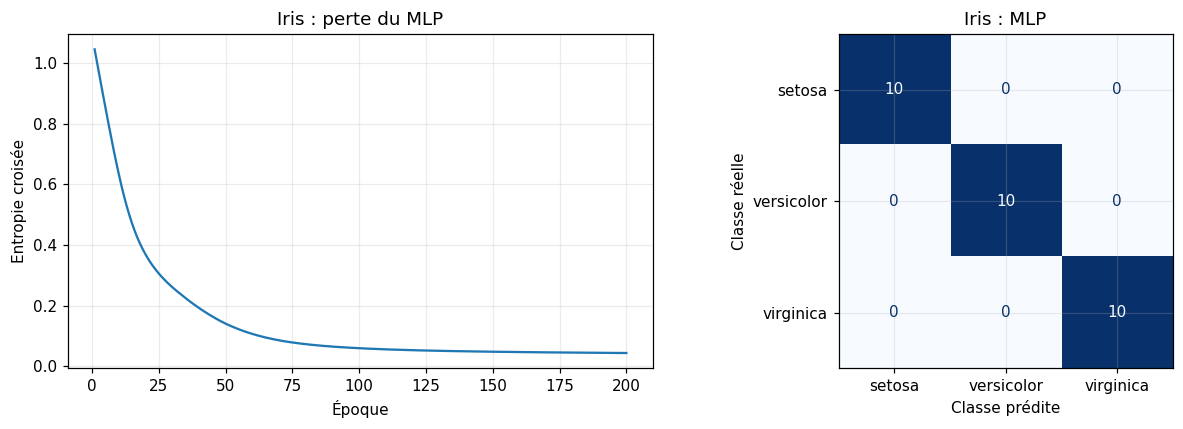

In [10]:
model_iris.eval()
with torch.no_grad():
    pred_iris = model_iris(X_test_i).argmax(dim=1).cpu().numpy()
accuracy_iris = accuracy_score(y_test_i_brut, pred_iris)
print(f"Accuracy MLP sur les 30 fleurs de test : {accuracy_iris:.2%}")
cm_iris = confusion_matrix(y_test_i_brut, pred_iris, labels=[0, 1, 2])
print("Matrice de confusion :\n", cm_iris)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 201), historique_iris)
axes[0].set(xlabel="Époque", ylabel="Entropie croisée", title="Iris : perte du MLP")
ConfusionMatrixDisplay(cm_iris, display_labels=iris.target_names).plot(
    ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set(xlabel="Classe prédite", ylabel="Classe réelle", title="Iris : MLP")
afficher_figure("ex2_perte_confusion.png")

### 4. Comparer avec un modèle sans couche cachée

**Consigne :** comparer ce réseau à **`nn.Linear(4, 3)`**, sur exactement les
mêmes données standardisées. On conserve Adam, `lr=0.01`, 200 époques et la même
perte ; la graine est réinitialisée avant la création du modèle linéaire.

Le modèle linéaire apprend des frontières affines. Le MLP peut apprendre des
frontières non linéaires et possède davantage de paramètres. La comparaison
porte sur un seul petit test de 30 fleurs : une fleur représente 3,33 points de
pourcentage. Elle ne suffit pas à établir une supériorité générale.

| Modèle | Paramètres | Accuracy test |
|---|---:|---:|
| MLP 4–16–3 | 131 | 100.00% |
| Linéaire 4–3 | 15 | 90.00% |

Écart MLP − linéaire : **+10.00 points** sur ce test et pour ce protocole fixé.

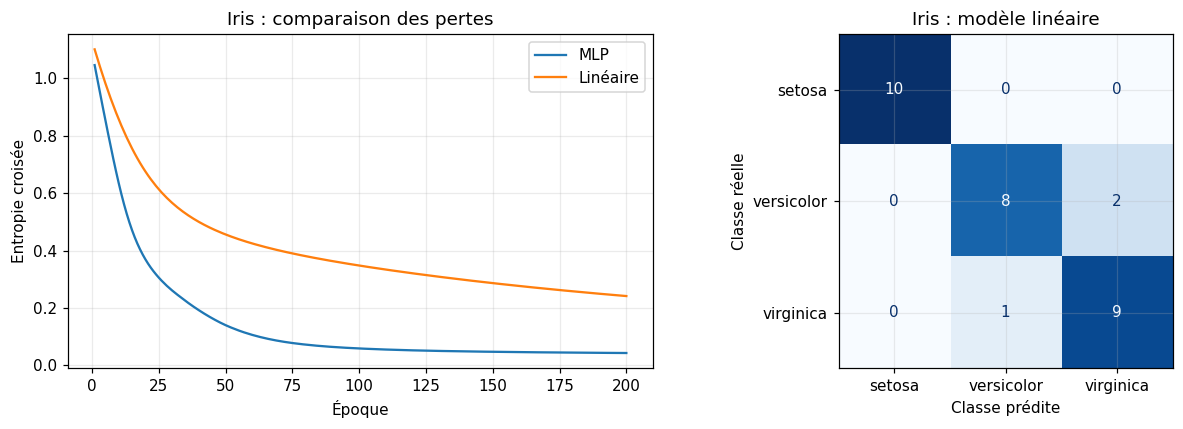

In [11]:
fixer_graines(42)
model_iris_lineaire = nn.Linear(4, 3).to(device)
optimizer_i_lin = torch.optim.Adam(model_iris_lineaire.parameters(), lr=0.01)
historique_i_lin = []
for epoch in range(200):
    model_iris_lineaire.train()
    optimizer_i_lin.zero_grad()
    loss = criterion_iris(model_iris_lineaire(X_train_i), y_train_i)
    loss.backward()
    optimizer_i_lin.step()
    historique_i_lin.append(loss.item())

model_iris_lineaire.eval()
with torch.no_grad():
    pred_i_lin = model_iris_lineaire(X_test_i).argmax(dim=1).cpu().numpy()
accuracy_i_lin = accuracy_score(y_test_i_brut, pred_i_lin)
parametres_iris = sum(p.numel() for p in model_iris.parameters())
parametres_i_lin = sum(p.numel() for p in model_iris_lineaire.parameters())
display(Markdown(
    "| Modèle | Paramètres | Accuracy test |\n|---|---:|---:|\n"
    f"| MLP 4–16–3 | {parametres_iris} | {accuracy_iris:.2%} |\n"
    f"| Linéaire 4–3 | {parametres_i_lin} | {accuracy_i_lin:.2%} |\n\n"
    f"Écart MLP − linéaire : **{100 * (accuracy_iris - accuracy_i_lin):+.2f} points** "
    "sur ce test et pour ce protocole fixé."
))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 201), historique_iris, label="MLP")
axes[0].plot(range(1, 201), historique_i_lin, label="Linéaire")
axes[0].set(xlabel="Époque", ylabel="Entropie croisée", title="Iris : comparaison des pertes")
axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test_i_brut, pred_i_lin,
    labels=[0, 1, 2], display_labels=iris.target_names, ax=axes[1],
    cmap="Blues", colorbar=False)
axes[1].set(xlabel="Classe prédite", ylabel="Classe réelle", title="Iris : modèle linéaire")
afficher_figure("ex2_comparaison.png")

### 5. Prédire une nouvelle fleur

**Consigne :** prédire l'espèce de **[5.1, 3.5, 1.4, 0.2]** après normalisation
par **le même scaler**. On utilise le MLP entraîné. Pour obtenir la classe,
`argmax` suffit ; aucun Softmax n'est nécessaire.

In [12]:
nouvelle_fleur = np.array([[5.1, 3.5, 1.4, 0.2]])
nouvelle_fleur_norm = torch.tensor(scaler_iris.transform(nouvelle_fleur),
                                  dtype=torch.float32, device=device)
model_iris.eval()
with torch.no_grad():
    classe_fleur = model_iris(nouvelle_fleur_norm).argmax(dim=1).item()
print("Mesures (cm) :", nouvelle_fleur[0])
print("Espèce prédite :", iris.target_names[classe_fleur], "| classe :", classe_fleur)

Mesures (cm) : [5.1 3.5 1.4 0.2]
Espèce prédite : setosa | classe : 0


## Exercice 3 — MLP : classification des chiffres MNIST

### 1. Charger les données et respecter les mini-lots

**Consignes :** utiliser `torchvision.datasets.MNIST`, `ToTensor()` seul, des lots
de **64** images pour le train (`shuffle=True`) et **256** pour le test
(`shuffle=False`). On utilise les **60 000** images de train et **10 000** de test,
sans sous-échantillonnage. `ToTensor()` donne des pixels flottants entre 0 et 1.

Le premier lancement télécharge MNIST dans `data/` si nécessaire. Les suivants
réutilisent ces fichiers. `num_workers=0` simplifie l'exécution sous Windows.
Un générateur propre au DataLoader rend le mélange reproductible.

In [13]:
fixer_graines(42)
transform_mlp = transforms.ToTensor()
train_mlp = datasets.MNIST(root=str(DOSSIER / "data"), train=True,
                           download=True, transform=transform_mlp)
test_mlp = datasets.MNIST(root=str(DOSSIER / "data"), train=False,
                          download=True, transform=transform_mlp)
generateur_mlp = torch.Generator().manual_seed(42)
loader_train_mlp = DataLoader(train_mlp, batch_size=64, shuffle=True,
    generator=generateur_mlp, num_workers=0)
loader_test_mlp = DataLoader(test_mlp, batch_size=256, shuffle=False, num_workers=0)
assert len(train_mlp) == 60000 and len(test_mlp) == 10000
print("MNIST train :", len(train_mlp), "| MNIST test :", len(test_mlp))
print("Image :", train_mlp[0][0].shape, "| classe :", train_mlp[0][1])
print("Batch sizes :", loader_train_mlp.batch_size, loader_test_mlp.batch_size)

MNIST train : 60000 | MNIST test : 10000
Image : torch.Size([1, 28, 28]) | classe : 5
Batch sizes : 64 256


### 2. Construire le MLP et définir les boucles

**Architecture imposée :** `Flatten → Linear(784, 128) → ReLU → Linear(128, 10)`.
**Apprentissage :** Adam, **`lr=0.001`**, `CrossEntropyLoss`, **5 époques**.
`Flatten` transforme chaque image $1\times28\times28$ en 784 valeurs.

Les deux fonctions ci-dessous seront aussi utilisées pour le CNN :
`train()` à chaque époque, remise à zéro des gradients, calcul des logits et de
la perte, `backward()`, puis `step()`. L'évaluation combine `eval()` et
`torch.no_grad()` : `eval()` seul ne coupe pas Autograd.

Les pertes moyennes sont pondérées par le nombre d'images de chaque lot.
La perte test est suivie à titre descriptif, sans sélection de modèle, d'époque
ou d'hyperparamètre : les durées d'entraînement sont fixées par l'énoncé.

In [14]:
def creer_mlp_mnist():
    return nn.Sequential(
        nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)
    )

def evaluer_images(model, loader, criterion):
    model.eval()
    perte_totale, correct, total = 0.0, 0, 0
    vrais, predits = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            predictions = logits.argmax(dim=1)
            perte_totale += criterion(logits, labels).item() * labels.size(0)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
            vrais.append(labels.cpu())
            predits.append(predictions.cpu())
    return {"perte": perte_totale / total, "accuracy": correct / total,
            "vrais": torch.cat(vrais), "predits": torch.cat(predits)}

def entrainer_images(model, loader_train, loader_test, epochs, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    historique = {"train": [], "test": []}
    if device.type == "cuda":
        torch.cuda.synchronize()
    debut = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for images, labels in loader_train:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
        perte_train = total_loss / len(loader_train.dataset)
        evaluation = evaluer_images(model, loader_test, criterion)
        historique["train"].append(perte_train)
        historique["test"].append(evaluation["perte"])
        print(f"Époque {epoch + 1}/{epochs} | Perte train : {perte_train:.4f} "
              f"| Perte test : {evaluation['perte']:.4f}", flush=True)
    if device.type == "cuda":
        torch.cuda.synchronize()
    duree = time.perf_counter() - debut
    return historique, evaluation, duree

model_mlp = creer_mlp_mnist().to(device)
print(model_mlp)
print("Paramètres :", sum(p.numel() for p in model_mlp.parameters()))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Paramètres : 101770


### 3. Entraîner pendant 5 époques et afficher les courbes de perte

**Consignes :** utiliser les mini-lots et `model.train()` pendant l'entraînement.
Les courbes montrent la perte moyenne train et la perte test mesurées à chaque
époque. La perte train agrège les lots rencontrés pendant les mises à jour,
tandis que la perte test est calculée avec les poids en fin d'époque ; leurs
valeurs ne sont donc pas strictement comparables point par point.

Époque 1/5 | Perte train : 0.3449 | Perte test : 0.1932


Époque 2/5 | Perte train : 0.1569 | Perte test : 0.1265


Époque 3/5 | Perte train : 0.1079 | Perte test : 0.1129


Époque 4/5 | Perte train : 0.0815 | Perte test : 0.0884


Époque 5/5 | Perte train : 0.0635 | Perte test : 0.0865


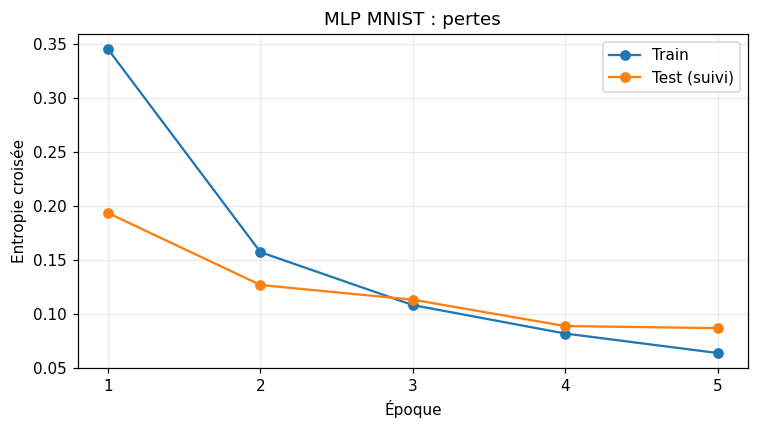

Durée entraînement et évaluations par époque : 60.5 s


In [15]:
historique_mlp, evaluation_mlp, duree_mlp = entrainer_images(
    model_mlp, loader_train_mlp, loader_test_mlp, epochs=5, lr=0.001
)
plt.plot(range(1, 6), historique_mlp["train"], marker="o", label="Train")
plt.plot(range(1, 6), historique_mlp["test"], marker="o", label="Test (suivi)")
plt.xticks(range(1, 6))
plt.xlabel("Époque")
plt.ylabel("Entropie croisée")
plt.title("MLP MNIST : pertes")
plt.legend()
afficher_figure("ex3_pertes.png")
print(f"Durée entraînement et évaluations par époque : {duree_mlp:.1f} s")

### 4. Accuracy, Precision, Recall, F1-score et matrice de confusion

**Consignes :** évaluer avec `model.eval()` et `torch.no_grad()`, obtenir les
classes par `argmax(dim=1)`, calculer les quatre métriques sur le **jeu de test**
et afficher la matrice de confusion.

L'accuracy compte les bonnes prédictions sur l'ensemble des images. Pour
Precision, Recall et F1, on retient la **moyenne macro** : calcul par classe,
puis moyenne non pondérée sur les **10 chiffres**. Chaque chiffre a ainsi le même
poids, même si les effectifs sont légèrement différents.

Pour une classe : $Precision=VP/(VP+FP)$, $Recall=VP/(VP+FN)$ et
$F1=2PR/(P+R)$. Le F1 macro est la moyenne des F1 par classe, pas le F1 recalculé
à partir des seules Precision et Recall macro. `zero_division=0` gère une
éventuelle classe jamais prédite. Les lignes de la matrice sont les vraies classes.

accuracy : 0.9735 (97.35%)
precision_macro : 0.9736 (97.36%)
recall_macro : 0.9733 (97.33%)
f1_macro : 0.9733 (97.33%)
Matrice de confusion :
 [[ 972    0    0    2    1    1    1    1    1    1]
 [   0 1124    3    1    0    1    2    1    3    0]
 [   6    3  994    8    4    0    2    6    8    1]
 [   0    0    0 1000    0    2    0    4    3    1]
 [   2    0    3    0  950    1    4    2    0   20]
 [   2    0    0   11    1  872    2    1    2    1]
 [  11    3    1    1    2   11  926    0    3    0]
 [   2    8    6   10    1    0    0  987    1   13]
 [   6    0    2   16    6    7    4    3  925    5]
 [   4    3    0   10    4    1    0    2    0  985]]


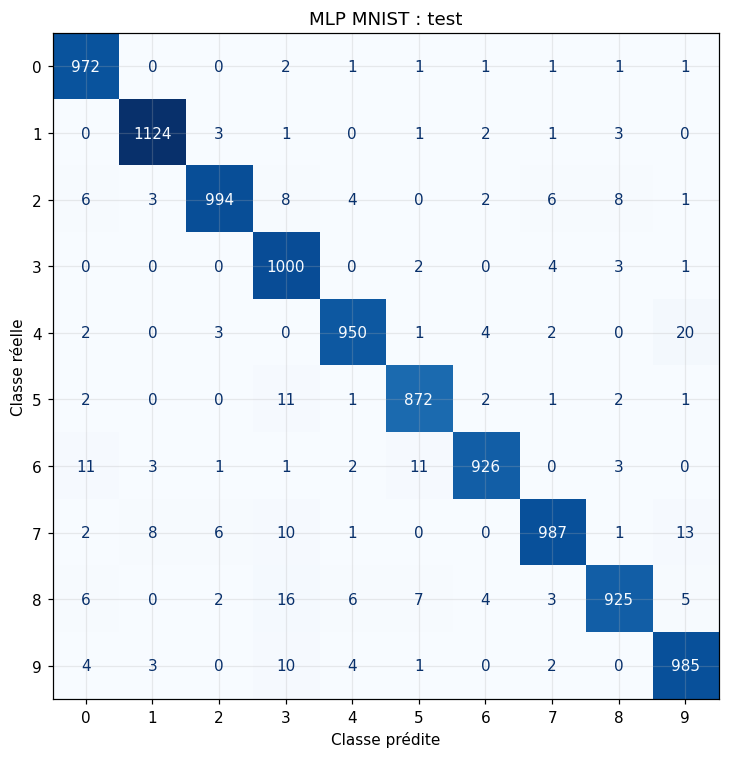

In [16]:
y_mlp = evaluation_mlp["vrais"].numpy()
pred_mlp = evaluation_mlp["predits"].numpy()
metriques_mlp = {
    "accuracy": accuracy_score(y_mlp, pred_mlp),
    "precision_macro": precision_score(y_mlp, pred_mlp, labels=list(range(10)),
                                       average="macro", zero_division=0),
    "recall_macro": recall_score(y_mlp, pred_mlp, labels=list(range(10)),
                                 average="macro", zero_division=0),
    "f1_macro": f1_score(y_mlp, pred_mlp, labels=list(range(10)),
                         average="macro", zero_division=0),
}
for nom, valeur in metriques_mlp.items():
    print(f"{nom} : {valeur:.4f} ({valeur:.2%})")
assert abs(metriques_mlp["accuracy"] - evaluation_mlp["accuracy"]) < 1e-12
cm_mlp = confusion_matrix(y_mlp, pred_mlp, labels=list(range(10)))
print("Matrice de confusion :\n", cm_mlp)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm_mlp, display_labels=list(range(10))).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set(xlabel="Classe prédite", ylabel="Classe réelle", title="MLP MNIST : test")
afficher_figure("ex3_confusion.png")

### 5. Afficher des images mal classées

**Consigne :** afficher quelques erreurs, avec leur vraie classe et la prédiction.
On prend les dix premières erreurs dans l'ordre fixe du test. Les indices du
dataset sont conservés car le DataLoader de test ne mélange pas les images.
Ces exemples illustrent les confusions, sans représenter à eux seuls toutes les
erreurs. La fonction remet les pixels dans [0, 1] si une normalisation a été faite.

MLP MNIST : images mal classées : 265 erreurs sur 10000 images.


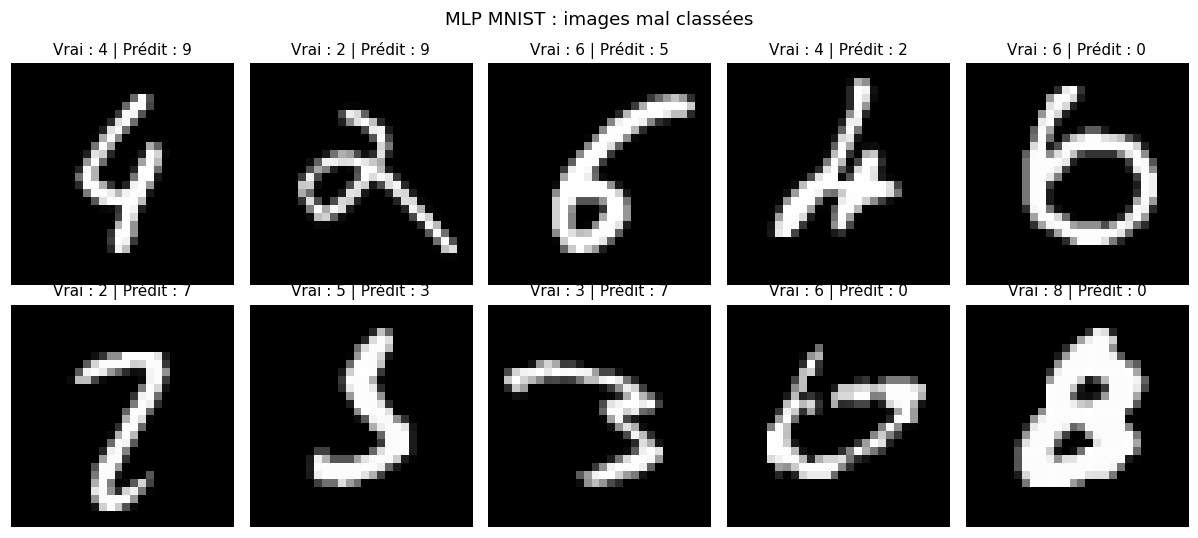

In [17]:
def afficher_erreurs(dataset, vrais, predits, titre, fichier, moyenne=0.0, ecart_type=1.0):
    indices_erreurs = torch.where(vrais != predits)[0]
    nombre = min(10, len(indices_erreurs))
    print(f"{titre} : {len(indices_erreurs)} erreurs sur {len(vrais)} images.")
    if nombre == 0:
        print("Aucune image mal classée à afficher.")
        return
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))
    for ax in axes.flat:
        ax.axis("off")
    for ax, indice in zip(axes.flat, indices_erreurs[:nombre].tolist()):
        image, vraie_classe = dataset[indice]
        image = image[0] * ecart_type + moyenne
        ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Vrai : {vraie_classe} | Prédit : {predits[indice].item()}", fontsize=10)
    fig.suptitle(titre)
    afficher_figure(fichier)

afficher_erreurs(test_mlp, evaluation_mlp["vrais"], evaluation_mlp["predits"],
                 "MLP MNIST : images mal classées", "ex3_erreurs.png")

### 6. Sauvegarder, recharger et vérifier les prédictions

**Consigne :** réutiliser le modèle sans recommencer l'apprentissage et vérifier
l'identité des prédictions après rechargement.

`state_dict()` contient les poids et biais. Il faut recréer la **même architecture**,
charger ces paramètres puis passer en `eval()`. `map_location=device` permet de
charger sur CPU ou GPU, et `weights_only=True` convient à ce fichier de poids.
La vérification porte sur **toutes les 10 000 images de test**, pas seulement un lot.

In [18]:
chemin_mlp = DOSSIER / "mnist_mlp.pth"
torch.save(model_mlp.state_dict(), chemin_mlp)
model_mlp_recharge = creer_mlp_mnist().to(device)
model_mlp_recharge.load_state_dict(
    torch.load(chemin_mlp, map_location=device, weights_only=True)
)
evaluation_mlp_recharge = evaluer_images(
    model_mlp_recharge, loader_test_mlp, nn.CrossEntropyLoss()
)
predictions_identiques_mlp = torch.equal(
    evaluation_mlp["predits"], evaluation_mlp_recharge["predits"]
)
assert predictions_identiques_mlp, "Les prédictions ont changé après rechargement."
print("Modèle sauvegardé :", chemin_mlp.name)
print("Prédictions identiques sur les 10 000 images :", predictions_identiques_mlp)

Modèle sauvegardé : mnist_mlp.pth
Prédictions identiques sur les 10 000 images : True


## Exercice 4 — Classification MNIST avec un CNN

### 1. Charger les données normalisées et visualiser des images

**Consignes :** `ToTensor()` puis **`Normalize((0.1307,), (0.3081,))`**, lots de
**64** au train et **256** au test ; afficher les dimensions et compléter
l'affichage des étiquettes de six images. On réutilise les fichiers MNIST locaux.

**Que représentent les quatre dimensions du tenseur `images` ?**
`[64, 1, 28, 28]` = taille du lot, canaux (un niveau de gris), hauteur, largeur.
Le dernier lot de train peut contenir moins de 64 images.

**Pourquoi mélanger les données d'entraînement avec `shuffle=True` ?**
Pour éviter de présenter toujours des lots dans le même ordre et réduire les
effets d'un éventuel classement des exemples. Un nouveau mélange est effectué
à chaque époque. Le test reste dans un ordre fixe.

Pour l'affichage seulement, on annule la normalisation :
$image = image_{norm}\times0.3081+0.1307$.

Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


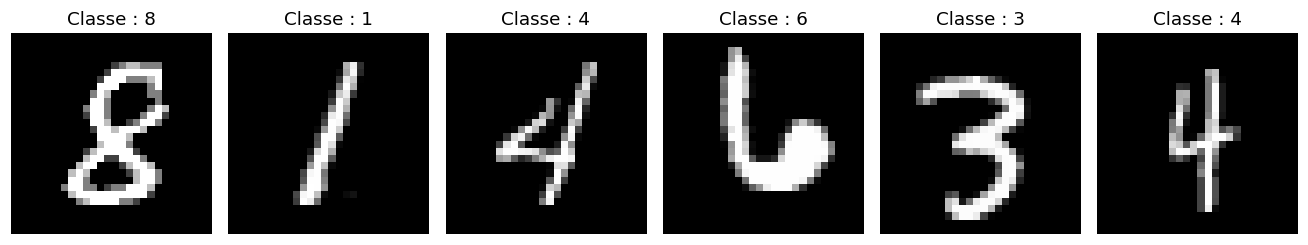

In [19]:
fixer_graines(42)
transform_cnn = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))
])
train_cnn = datasets.MNIST(root=str(DOSSIER / "data"), train=True,
                           download=True, transform=transform_cnn)
test_cnn = datasets.MNIST(root=str(DOSSIER / "data"), train=False,
                          download=True, transform=transform_cnn)
generateur_cnn = torch.Generator().manual_seed(42)
loader_train_cnn = DataLoader(train_cnn, batch_size=64, shuffle=True,
    generator=generateur_cnn, num_workers=0)
loader_test_cnn = DataLoader(test_cnn, batch_size=256, shuffle=False, num_workers=0)
images_cnn, labels_cnn = next(iter(loader_train_cnn))
print("Images :", images_cnn.shape)
print("Labels :", labels_cnn.shape)
assert images_cnn.shape == (64, 1, 28, 28)
assert torch.equal(test_mlp.targets, test_cnn.targets)
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i, ax in enumerate(axes):
    image = images_cnn[i, 0] * 0.3081 + 0.1307
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels_cnn[i].item()}")
    ax.axis("off")
afficher_figure("ex4_images.png")

### 2. Construire exactement le CNN demandé

**Architecture :** `Conv2d(1,16,3,padding=1) → ReLU → MaxPool2d(2) →
Conv2d(16,32,3,padding=1) → ReLU → MaxPool2d(2) → Flatten →
Linear(1568,128) → ReLU → Linear(128,10)`.

**Pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?**
Le padding 1 conserve la taille spatiale pour les convolutions de noyau 3 et
de stride 1 : $28\to28$, puis $14\to14$. Chaque pooling divise hauteur et
largeur par deux : $28\to14\to7$. Il reste **32 cartes de 7 × 7 pixels**, donc
$32\times7\times7=1568$ valeurs par image après aplatissement.

Aucun Softmax n'est ajouté. Le paramètre facultatif `dropout` servira uniquement
à l'expérience supplémentaire ; avec sa valeur par défaut `None`, le modèle
contient exactement les couches imposées, sans couche ajoutée.

In [20]:
class MNISTClassifier(nn.Module):
    def __init__(self, dropout=None):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        couches = [nn.Flatten(), nn.Linear(1568, 128), nn.ReLU()]
        if dropout is not None:
            couches.append(nn.Dropout(p=dropout))
        couches.append(nn.Linear(128, 10))
        self.classifier = nn.Sequential(*couches)

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

fixer_graines(42)
model_cnn = MNISTClassifier().to(device)
parametres_initiaux_cnn = [p.detach().cpu().clone() for p in model_cnn.parameters()]
model_cnn.eval()
with torch.no_grad():
    cartes = model_cnn.features(images_cnn.to(device))
    output = model_cnn(images_cnn.to(device))
assert cartes.shape == (64, 32, 7, 7)
assert output.shape == (images_cnn.size(0), 10)
print(model_cnn)
print("Cartes après convolutions et pooling :", cartes.shape)
print("Sortie :", output.shape)
print("Paramètres :", sum(p.numel() for p in model_cnn.parameters()))

MNISTClassifier(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Cartes après convolutions et pooling : torch.Size([64, 32, 7, 7])
Sortie : torch.Size([64, 10])
Paramètres : 206922


### 3. Entraîner pendant 3 époques

**Consignes :** Adam, **`lr=0.001`**, `CrossEntropyLoss`, **3 époques**.
La boucle `entrainer_images` réalise les cinq étapes demandées dans l'énoncé :
`zero_grad()`, calcul des logits, calcul de la perte, `backward()`, `step()`.
On réinitialise le générateur du DataLoader après l'aperçu des six images,
pour ne pas décaler l'ordre des lots d'entraînement.

Époque 1/3 | Perte train : 0.1682 | Perte test : 0.0617


Époque 2/3 | Perte train : 0.0499 | Perte test : 0.0396


Époque 3/3 | Perte train : 0.0347 | Perte test : 0.0425


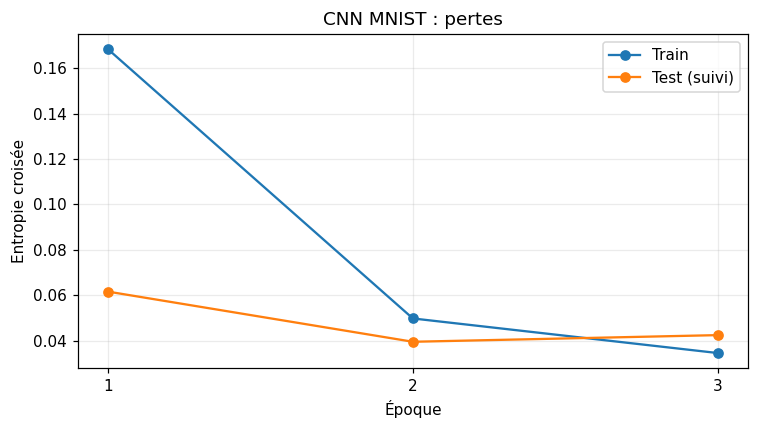

Durée entraînement et évaluations par époque : 74.4 s


In [21]:
generateur_cnn.manual_seed(42)
historique_cnn, evaluation_cnn, duree_cnn = entrainer_images(
    model_cnn, loader_train_cnn, loader_test_cnn, epochs=3, lr=0.001
)
plt.plot(range(1, 4), historique_cnn["train"], marker="o", label="Train")
plt.plot(range(1, 4), historique_cnn["test"], marker="o", label="Test (suivi)")
plt.xticks(range(1, 4))
plt.xlabel("Époque")
plt.ylabel("Entropie croisée")
plt.title("CNN MNIST : pertes")
plt.legend()
afficher_figure("ex4_pertes.png")
print(f"Durée entraînement et évaluations par époque : {duree_cnn:.1f} s")

### 4. Évaluer et afficher 10 images mal classées

**Consignes :** calculer l'accuracy sur le test avec `eval()` et `no_grad()` ;
sélectionner les classes avec `argmax(dim=1)` ; compter les bonnes réponses avec
`(predictions == labels).sum().item()` ; afficher dix erreurs avec leurs vraies
classes et prédictions. Ces opérations sont réalisées dans `evaluer_images`.

L'énoncé indique qu'une accuracy supérieure à 97 % est fréquente ; cette valeur
n'est pas garantie. Seule la valeur réellement calculée est rapportée ici.

Bonnes prédictions : 9848 / 10000
Accuracy CNN sur le test : 98.48%
CNN MNIST : 10 images mal classées : 152 erreurs sur 10000 images.


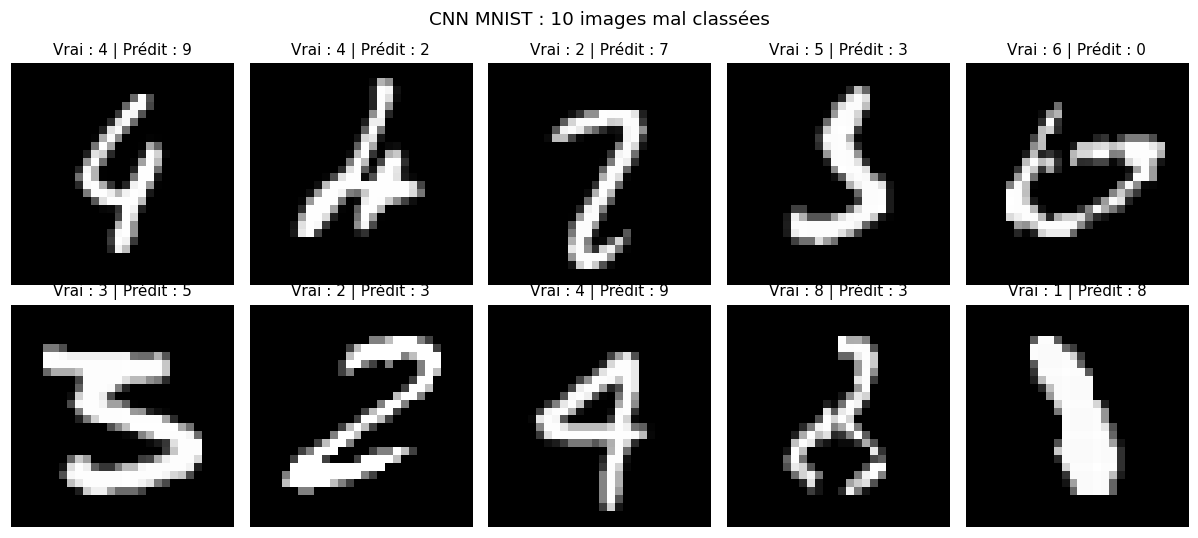

In [22]:
accuracy_cnn = evaluation_cnn["accuracy"]
correct_cnn = (evaluation_cnn["predits"] == evaluation_cnn["vrais"]).sum().item()
total_cnn = len(evaluation_cnn["vrais"])
assert total_cnn == 10000
print(f"Bonnes prédictions : {correct_cnn} / {total_cnn}")
print(f"Accuracy CNN sur le test : {accuracy_cnn:.2%}")
afficher_erreurs(test_cnn, evaluation_cnn["vrais"], evaluation_cnn["predits"],
    "CNN MNIST : 10 images mal classées", "ex4_erreurs.png",
    moyenne=0.1307, ecart_type=0.3081)

### 5. Tester une variante avec Dropout

**Consigne :** ajouter Dropout **avant la dernière couche linéaire**, puis tester
la variante. Le taux n'étant pas imposé, on choisit **`p=0.5`**, comme dans
l'exemple du support (page 19). On entraîne cette variante **depuis le début**
pendant les mêmes **3 époques**, avec Adam, `lr=0.001`, et la même normalisation.
La graine et le générateur des lots sont réinitialisés : les paramètres initiaux
et l'ordre des lots correspondent à ceux du CNN de base.

En `train()`, Dropout annule aléatoirement la moitié des activations en moyenne
et multiplie celles conservées par 2. En `eval()`, il est désactivé. Cette
régularisation peut limiter le surapprentissage ; elle ne garantit pas une
meilleure accuracy après seulement trois époques. Le test sert à rapporter les
résultats, sans choisir le taux ni sélectionner le modèle sur cette base.

Paramètres initiaux identiques à ceux du CNN de base : vérifié.
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=1568, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=128, out_features=10, bias=True)
)


Époque 1/3 | Perte train : 0.2464 | Perte test : 0.0596


Époque 2/3 | Perte train : 0.0884 | Perte test : 0.0393


Époque 3/3 | Perte train : 0.0667 | Perte test : 0.0321


| CNN | Époques | Accuracy test |
|---|---:|---:|
| Sans Dropout | 3 | 98.48% |
| Avec Dropout p=0.5 | 3 | 98.93% |

Écart avec − sans Dropout : **+0.45 points**. C'est le résultat d'un entraînement par variante, sans garantie de généralisation.

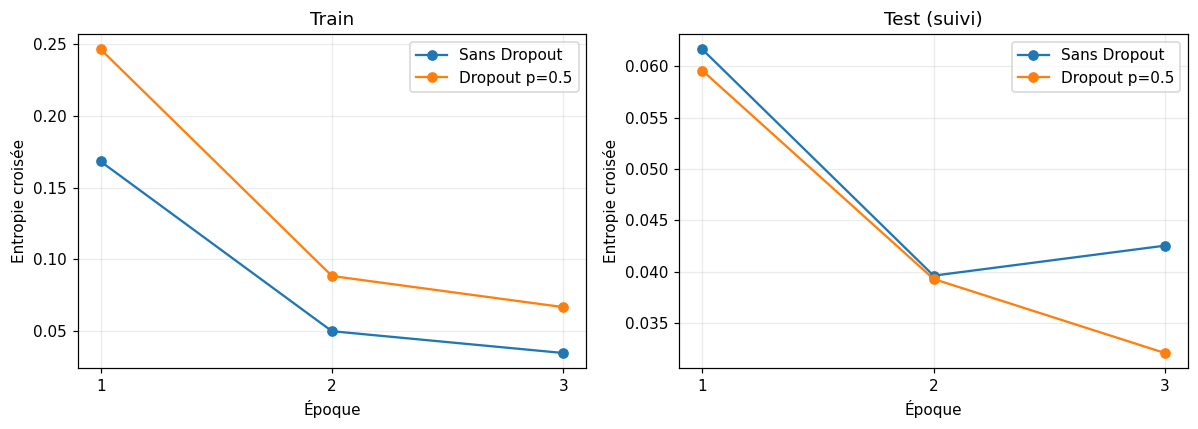

In [23]:
fixer_graines(42)
model_cnn_dropout = MNISTClassifier(dropout=0.5).to(device)
assert all(torch.equal(initial, variante.detach().cpu())
           for initial, variante in zip(parametres_initiaux_cnn, model_cnn_dropout.parameters()))
print("Paramètres initiaux identiques à ceux du CNN de base : vérifié.")
generateur_dropout = torch.Generator().manual_seed(42)
loader_train_dropout = DataLoader(train_cnn, batch_size=64, shuffle=True,
    generator=generateur_dropout, num_workers=0)
print(model_cnn_dropout.classifier)
historique_dropout, evaluation_dropout, duree_dropout = entrainer_images(
    model_cnn_dropout, loader_train_dropout, loader_test_cnn, epochs=3, lr=0.001
)
accuracy_dropout = evaluation_dropout["accuracy"]
display(Markdown(
    "| CNN | Époques | Accuracy test |\n|---|---:|---:|\n"
    f"| Sans Dropout | 3 | {accuracy_cnn:.2%} |\n"
    f"| Avec Dropout p=0.5 | 3 | {accuracy_dropout:.2%} |\n\n"
    f"Écart avec − sans Dropout : **{100 * (accuracy_dropout - accuracy_cnn):+.2f} points**. "
    "C'est le résultat d'un entraînement par variante, sans garantie de généralisation."
))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cle, titre in zip(axes, ["train", "test"], ["Train", "Test (suivi)"]):
    ax.plot(range(1, 4), historique_cnn[cle], marker="o", label="Sans Dropout")
    ax.plot(range(1, 4), historique_dropout[cle], marker="o", label="Dropout p=0.5")
    ax.set(xlabel="Époque", ylabel="Entropie croisée", title=titre, xticks=[1, 2, 3])
    ax.legend()
afficher_figure("ex4_dropout.png")

### 6. Sauvegarder le CNN de base dans `mnist_cnn.pth`

**Consigne :** sauvegarder les paramètres avec
`torch.save(model.state_dict(), "mnist_cnn.pth")`.
On sauvegarde le **CNN sans Dropout**, qui respecte exactement l'architecture
principale, dans ce fichier. La variante a son propre fichier
`mnist_cnn_dropout.pth`. On vérifie aussi le rechargement du CNN de base sur
l'intégralité du test. Pour la variante, recréer `MNISTClassifier(dropout=0.5)`
avant d'en charger les poids.

In [24]:
torch.save(model_cnn.state_dict(), DOSSIER / "mnist_cnn.pth")
torch.save(model_cnn_dropout.state_dict(), DOSSIER / "mnist_cnn_dropout.pth")
model_cnn_recharge = MNISTClassifier().to(device)
model_cnn_recharge.load_state_dict(torch.load(
    DOSSIER / "mnist_cnn.pth", map_location=device, weights_only=True
))
evaluation_cnn_recharge = evaluer_images(
    model_cnn_recharge, loader_test_cnn, nn.CrossEntropyLoss()
)
predictions_identiques_cnn = torch.equal(
    evaluation_cnn["predits"], evaluation_cnn_recharge["predits"]
)
assert predictions_identiques_cnn
print("Fichiers sauvegardés : mnist_cnn.pth et mnist_cnn_dropout.pth")
print("CNN rechargé : prédictions identiques sur les 10 000 images :",
      predictions_identiques_cnn)

Fichiers sauvegardés : mnist_cnn.pth et mnist_cnn_dropout.pth
CNN rechargé : prédictions identiques sur les 10 000 images : True


### 7. Courte comparaison du MLP et du CNN

Le MLP aplatit l'image et relie chaque pixel à chaque neurone caché. Le CNN
exploite les voisinages spatiaux et partage ses filtres entre les positions.
Ces propriétés sont adaptées aux contours et traits des chiffres manuscrits.

La comparaison ci-dessous respecte les protocoles du professeur : **MLP 5 époques
avec `ToTensor()` seul**, **CNN 3 époques avec normalisation (0.1307, 0.3081)**.
Elle compare donc les résultats de ces deux protocoles, sans isoler l'effet de
la seule architecture. Les temps incluent l'entraînement et une évaluation test
par époque ; ils dépendent du matériel et ne constituent pas un benchmark général.

In [25]:
nb_param_mlp = sum(p.numel() for p in model_mlp.parameters())
nb_param_cnn = sum(p.numel() for p in model_cnn.parameters())
display(Markdown(
    "| Modèle | Époques | Paramètres | Accuracy test | Temps mesuré (s) |\n"
    "|---|---:|---:|---:|---:|\n"
    f"| MLP | 5 | {nb_param_mlp} | {metriques_mlp['accuracy']:.2%} | {duree_mlp:.1f} |\n"
    f"| CNN | 3 | {nb_param_cnn} | {accuracy_cnn:.2%} | {duree_cnn:.1f} |\n"
    f"| CNN + Dropout | 3 | {sum(p.numel() for p in model_cnn_dropout.parameters())} "
    f"| {accuracy_dropout:.2%} | {duree_dropout:.1f} |\n\n"
    f"Écart CNN − MLP : **{100 * (accuracy_cnn - metriques_mlp['accuracy']):+.2f} points**. "
    f"Erreurs sur 10 000 images : **{int((y_mlp != pred_mlp).sum())}** pour le MLP "
    f"et **{total_cnn - correct_cnn}** pour le CNN."
))

| Modèle | Époques | Paramètres | Accuracy test | Temps mesuré (s) |
|---|---:|---:|---:|---:|
| MLP | 5 | 101770 | 97.35% | 60.5 |
| CNN | 3 | 206922 | 98.48% | 74.4 |
| CNN + Dropout | 3 | 206922 | 98.93% | 74.8 |

Écart CNN − MLP : **+1.13 points**. Erreurs sur 10 000 images : **265** pour le MLP et **152** pour le CNN.

## Vérification finale et bilan

Les quatre exercices ont été traités dans l'ordre. Toutes les questions de
l'énoncé sont reprises dans leurs sections : coefficients et limites de la
régression, préparation d'Iris, dimensions et mélange des lots, dimensions
internes du CNN, expérience Dropout et sauvegardes.

Les cellules suivantes doivent terminer sans exception lors d'un **redémarrage du
noyau suivi de « Tout exécuter »**. Les métriques, hyperparamètres et contrôles
essentiels sont exportés dans `resultats_tp1.json`. Les figures restent aussi
enregistrées dans `figures/`. Une graine et les calculs déterministes améliorent
la reproductibilité ; des versions ou un matériel différents peuvent néanmoins
modifier les valeurs numériques.

In [26]:
assert len(historique_salaire) == 500
assert len(historique_iris) == len(historique_i_lin) == 200
assert len(historique_mlp["train"]) == 5
assert len(historique_cnn["train"]) == len(historique_dropout["train"]) == 3
assert len(evaluation_mlp["vrais"]) == len(evaluation_cnn["vrais"]) == 10000
assert predictions_identiques_mlp and predictions_identiques_cnn
assert not any(isinstance(couche, nn.Softmax) for model in
    [model_iris, model_iris_lineaire, model_mlp, model_cnn, model_cnn_dropout]
    for couche in model.modules())
assert all(np.isfinite(valeur) for historique in
    [historique_salaire, historique_iris, historique_i_lin,
     historique_mlp["train"], historique_cnn["train"], historique_dropout["train"]]
    for valeur in historique)
for nom in ["mnist_mlp.pth", "mnist_cnn.pth", "mnist_cnn_dropout.pth"]:
    assert (DOSSIER / nom).is_file()

resultats = {
    "environnement": {"python": sys.version.split()[0], "torch": torch.__version__,
        "torchvision": torchvision.__version__, "numpy": np.__version__,
        "scikit_learn": sklearn.__version__, "device": str(device), "graine": 42},
    "exercice_1": {"mae_dh": mae_salaire, "salaire_7_ans_expertise_4_dh": salaire_predit,
        "coefficients_dh": coefficients_dh.tolist(), "biais_dh": biais_dh,
        "epochs": 500, "lr": 0.05, "train": 240, "test": 60},
    "exercice_2": {"accuracy_mlp": accuracy_iris, "accuracy_lineaire": accuracy_i_lin,
        "espece_predite": str(iris.target_names[classe_fleur]), "epochs": 200, "lr": 0.01},
    "exercice_3": {**metriques_mlp, "moyennage": "macro", "epochs": 5, "lr": 0.001,
        "batch_train": 64, "batch_test": 256, "duree_secondes": duree_mlp,
        "rechargement_identique": predictions_identiques_mlp},
    "exercice_4": {"accuracy": accuracy_cnn, "accuracy_dropout": accuracy_dropout,
        "dropout_p": 0.5, "epochs_par_modele": 3, "lr": 0.001,
        "batch_train": 64, "batch_test": 256, "normalisation": [0.1307, 0.3081],
        "duree_secondes": duree_cnn, "duree_dropout_secondes": duree_dropout,
        "rechargement_identique": predictions_identiques_cnn},
}
(DOSSIER / "resultats_tp1.json").write_text(
    json.dumps(resultats, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Vérifications internes réussies : 4 exercices complets, pertes finies,")
print("durées et hyperparamètres respectés, modèles sauvegardés et rechargements vérifiés.")
print("Résultats exportés dans resultats_tp1.json.")

Vérifications internes réussies : 4 exercices complets, pertes finies,
durées et hyperparamètres respectés, modèles sauvegardés et rechargements vérifiés.
Résultats exportés dans resultats_tp1.json.
